Observations (train): 307,511
Observations (test):  48,744
Variables:            121
Missing values:       9,152,465 (24.4% of all cells)
Duplicates:           0
Numeric features:     105
Categorical features: 16


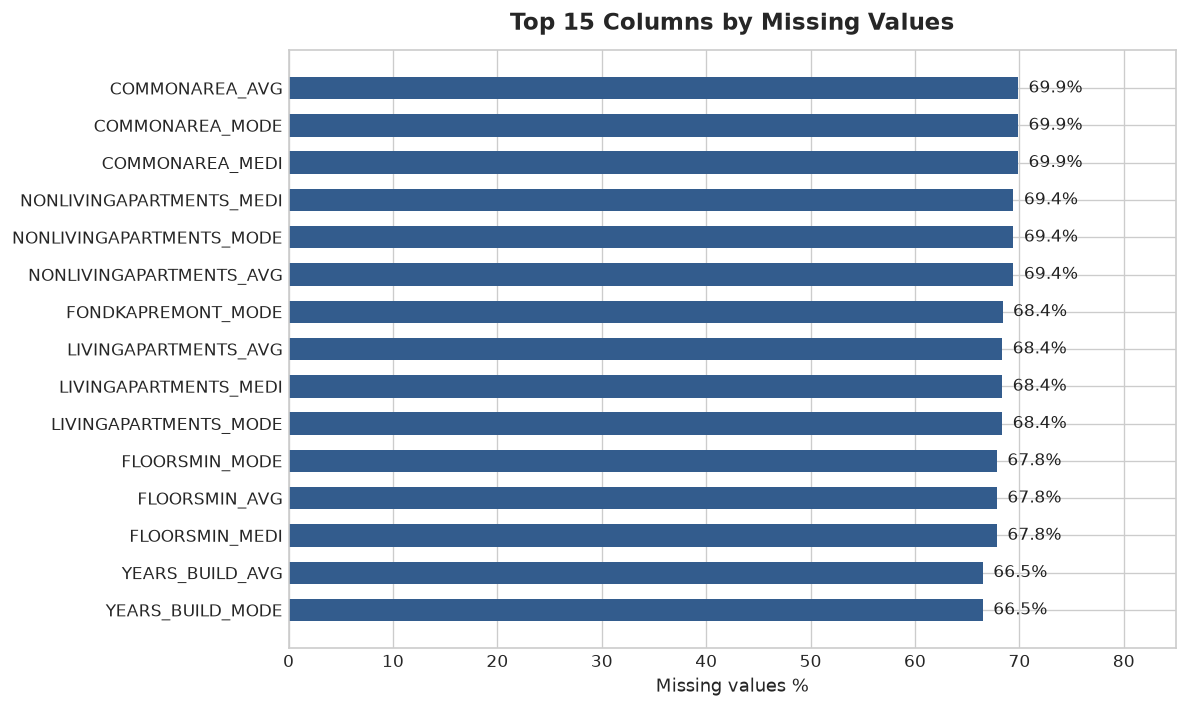


==================== Logistic Regression ====================
Baseline ROC-AUC: 0.74879 (час: 19.33 с)
Tuned ROC-AUC:    0.74881 (час: 323.93 с)
Кращі параметри: {'solver': 'lbfgs', 'C': np.float64(0.1668100537200059)}

==================== Decision Tree ====================
Baseline ROC-AUC: 0.54267 (час: 21.68 с)
Tuned ROC-AUC:    0.72023 (час: 63.32 с)
Кращі параметри: {'min_samples_leaf': 100, 'max_depth': 8, 'criterion': 'entropy'}

==================== Random Forest ====================
Baseline ROC-AUC: 0.73373 (час: 13.98 с)


In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

from data_preprocessing import get_dataset_stats, print_stats_summary, prepare_pipeline
from models.logistic_regression import LogisticRegressionTrainer
from models.decision_tree import DecisionTreeTrainer
from models.random_forest import RandomForestTrainer
from models.gradient_boosting import GradientBoostingTrainer
from models.neural_network import NeuralNetworkTrainer

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

train_df = pd.read_csv('application_train.csv')
test_df = pd.read_csv('application_test.csv')

stats = get_dataset_stats(train_df, test_df)
print_stats_summary(stats)

missing_per_col = (train_df.isnull().sum() / len(train_df)) * 100
top15_missing = missing_per_col.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
bars = plt.barh(top15_missing.index[::-1], top15_missing.values[::-1], color='#335c8d', height=0.6)
plt.title('Top 15 Columns by Missing Values', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Missing values %', fontsize=11)
plt.xlim(0, 85)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.0, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', ha='left', fontsize=10, color='#222222')

plt.tight_layout()
plt.show()

data = prepare_pipeline(train_df, test_df)

models = {}
roc_curves = {}
summary_metrics = []

def run_evaluation(name, trainer_obj, X_tr, X_va):
    print(f"\n==================== {name} ====================")
    t0 = time.time()
    auc_base = trainer_obj.fit_baseline(X_tr, data['y_train'], X_va, data['y_val'])
    t_base = time.time() - t0
    print(f"Baseline ROC-AUC: {auc_base:.5f} (час: {t_base:.2f} с)")
    
    t0 = time.time()
    auc_tuned, best_params = trainer_obj.tune(X_tr, data['y_train'], X_va, data['y_val'])
    t_tune = time.time() - t0
    print(f"Tuned ROC-AUC:    {auc_tuned:.5f} (час: {t_tune:.2f} с)")
    print(f"Кращі параметри: {best_params}")
    
    preds = trainer_obj.predict_proba(X_va)
    fpr, tpr, _ = roc_curve(data['y_val'], preds)
    roc_curves[name] = (fpr, tpr, auc_tuned)
    models[name] = trainer_obj
    
    summary_metrics.append({
        'Model': name,
        'Baseline ROC-AUC': round(auc_base, 5),
        'Tuned ROC-AUC': round(auc_tuned, 5),
        'Baseline Time (s)': round(t_base, 2),
        'Tuning Time (s)': round(t_tune, 2),
        'Best Params': str(best_params)
    })

run_evaluation("Logistic Regression", LogisticRegressionTrainer(), data['X_train_scaled'], data['X_val_scaled'])
run_evaluation("Decision Tree", DecisionTreeTrainer(), data['X_train'], data['X_val'])
run_evaluation("Random Forest", RandomForestTrainer(), data['X_train'], data['X_val'])
run_evaluation("LightGBM", GradientBoostingTrainer(), data['X_train'], data['X_val'])
run_evaluation("Neural Network (MLP)", NeuralNetworkTrainer(), data['X_train_scaled'], data['X_val_scaled'])

plt.figure(figsize=(9, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for (name, (fpr, tpr, auc_score)), color in zip(roc_curves.items(), colors):
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})', lw=2, color=color)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.5)')
plt.title('ROC Curves Comparison (Validation Set)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

df_summary = pd.DataFrame(summary_metrics)
print("\n================ FINAL RESULTS SUMMARY ================")
print(df_summary[['Model', 'Baseline ROC-AUC', 'Tuned ROC-AUC', 'Baseline Time (s)', 'Tuning Time (s)']])

lgb_trainer = models['LightGBM']
df_imp = lgb_trainer.get_feature_importance(data['feature_names']).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_imp, x='importance', y='feature', palette='viridis')
plt.title('LightGBM Feature Importance (Top 15)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Split Count Importance', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.tight_layout()
plt.show()

best_row = df_summary.sort_values(by='Tuned ROC-AUC', ascending=False).iloc[0]
best_name = best_row['Model']
best_trainer = models[best_name]

X_test_final = data['X_test_scaled'] if "Logistic" in best_name or "Neural" in best_name else data['X_test_imputed']
test_preds = best_trainer.predict_proba(X_test_final)

submission = pd.DataFrame({'SK_ID_CURR': data['test_ids'], 'TARGET': test_preds})
submission.to_csv('submission.csv', index=False)
print("Saved submission.csv successfully!")